# Docs figures: drift of the LI-7500 storage term (L3.1)

**notebook version**: `1` (6 Nov 2026)

## ℹ️ About this notebook

Draws the figure `@fig-l31-storage-drift` of the documentation page *Level 3.1* (`docs/L3.1.md`) and
writes it to `docs/images/STORAGE_IRGA75_drift.png`.

The storage term of the open-path LI-7500 drifts: with wet or blocked windows the analyser reads too
high a CO2 concentration around its gaps. The reading rises inside a gap, where no storage term is
computed, and returns after it, which enters the single-point storage term as a negative flux. The
figure shows one such gap in the parallel period of both analysers and the cumulative storage term
of the period, without and with the concentration screen of the flux chain.

**Data used** (external data folder):

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019`:
  `CO2_MIXING_RATIO` and `SC_SINGLE` of the LI-7500, before any screening
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/00_FPPC_IRGA72_INPUT_2016-2026.09`: the same of the LI-7200
- `05_FPPC_IRGA75_NEE_OPCO_2004-2017` and `05_FPPC_IRGA72_NEE_2016-2026.09`:
  `SC_SINGLE_gfRMED_L3.1`, the storage term after the screening of the chain
- `10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09`: `PREC_TOT_T1_47_1_HOMOGENIZED`

Run it after `IRGA75/05` and `IRGA72/05`. The figure is saved as the page shows it; the caption below
it in this notebook is added afterwards and is not part of the file.

## ⚙️ Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # the repository root, two levels above this notebook
OUT = ROOT / 'docs' / 'images'
DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
STAGE = DATADIR / '30_FLUX_POST-PROCESSING_CHAIN'
FILES = {
    'raw75': STAGE / 'IRGA75' / '01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet',
    'raw72': STAGE / 'IRGA72' / '00_FPPC_IRGA72_INPUT_2016-2026.09.parquet',
    'chain75': STAGE / 'IRGA75' / '05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet',
    'chain72': STAGE / 'IRGA72' / '05_FPPC_IRGA72_NEE_2016-2026.09.parquet',
    'meteo': DATADIR / '10_METEO' / '30_PRODUCTS' / '99_METEO_MERGED_2004-2026.09.parquet',
}
CO2, SC, SC_CHAIN = 'CO2_MIXING_RATIO', 'SC_SINGLE', 'SC_SINGLE_gfRMED_L3.1'
PREC = 'PREC_TOT_T1_47_1_HOMOGENIZED'

# Calibration offset of the LI-7500 against the LI-7200 in the parallel period (docs/L3.1.md, Cause).
OFFSET75 = 8.7  # ppm
PARALLEL = ('2016-01-11', '2017-12-12')
# A typical gap, chosen among the gaps of 3 to 16 records of the parallel period with complete
# LI-7200 data: before it the LI-7500 reads within a few ppm of the LI-7200, the first record after
# it about 90 ppm above, and it is back within a few records.
EXAMPLE = ('2016-06-14 20:00', '2016-06-15 20:00')
UMOL_TO_GC = 12.011e-6 * 1800  # umol m-2 s-1 over a half-hour -> gC m-2

INK, MUTED, GRID = '#1F2623', '#5A6460', '#E4E7E4'
C75, C75_SCREENED, C72 = '#C96F2B', '#2E6A4E', '#2B6CA3'
GAP, RAIN = '#E6E8E6', '#7FA7CF'

In [2]:
from datetime import datetime
import textwrap

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({'font.size': 10, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 150, 'figure.dpi': 100})

def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


def save_for_docs(fig, name):
    """Write the figure as the docs page shows it, before the notebook caption is added."""
    path = OUT / name
    fig.savefig(path)
    print(f"written: {path.relative_to(ROOT)}")
    return path


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")

Last run: 2026-11-06 16:03:55


## 📂 Load data

In [3]:
def load(key, cols):
    df = pd.read_parquet(FILES[key], columns=cols).replace(-9999, np.nan)
    df.index = pd.DatetimeIndex(df.index)
    assert not df.index.duplicated().any(), f"{key}: duplicate timestamps"
    print(f"{key}: {FILES[key].name}, {df.index[0]} -> {df.index[-1]}")
    return df


raw75, raw72 = load('raw75', [CO2, SC]), load('raw72', [CO2, SC])
sc75, sc72 = load('chain75', [SC_CHAIN])[SC_CHAIN], load('chain72', [SC_CHAIN])[SC_CHAIN]
prec = load('meteo', [PREC])[PREC]

raw75: 01_FPPC_IRGA75_OPEN-PATH_CORRECTION_2004-2017_2019.parquet, 2004-01-01 00:15:00 -> 2019-12-31 23:45:00
raw72: 00_FPPC_IRGA72_INPUT_2016-2026.09.parquet, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
chain75: 05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet, 2004-01-01 00:15:00 -> 2017-12-31 23:45:00
chain72: 05_FPPC_IRGA72_NEE_2016-2026.09.parquet, 2016-01-01 00:15:00 -> 2026-09-30 23:45:00
meteo: 99_METEO_MERGED_2004-2026.09.parquet, 2004-01-01 00:15:00 -> 2026-09-30 23:45:00


## 🔍 Check the example and the offset

In [4]:
# The example must show what the page says: the LI-7200 complete, the LI-7500 within a few ppm of
# it before the longest gap of the window, far above it in the first record after it, and back
# within a few records. The offset is the median difference of the two analysers in the parallel
# period, which the page gives as 8.7 ppm after the calibration of the LI-7500.
_p = slice(*PARALLEL)
_offset = (raw75.loc[_p, CO2] - raw72.loc[_p, CO2]).median()
print(f"median LI-7500 minus LI-7200 in the parallel period: {_offset:.1f} ppm (declared {OFFSET75})")
assert abs(_offset - OFFSET75) < 2, "the declared offset no longer matches the data"

_w = slice(*EXAMPLE)
_c75, _c72 = raw75.loc[_w, CO2] - OFFSET75, raw72.loc[_w, CO2]
assert _c72.notna().all(), "the LI-7200 has gaps in the example window"
_miss = _c75.isna()
GAPS = [g.index for _, g in _c75[_miss].groupby((_miss != _miss.shift()).cumsum()[_miss])]
GAP_MAIN = max(GAPS, key=len)
I0, I1 = _c75.index.get_loc(GAP_MAIN[0]) - 1, _c75.index.get_loc(GAP_MAIN[-1]) + 1
_dev = (_c75 - _c72)
print(f"longest gap {GAP_MAIN[0]} to {GAP_MAIN[-1]}: LI-7500 minus LI-7200 {_dev.iloc[I0]:+.1f} ppm before, "
      f"{_dev.iloc[I1]:+.1f} ppm after, {_dev.iloc[I1 + 4]:+.1f} ppm four records later")
assert abs(_dev.iloc[I0]) < 15 and _dev.iloc[I1] > 40 and abs(_dev.iloc[I1 + 4]) < 15

median LI-7500 minus LI-7200 in the parallel period: 10.1 ppm (declared 8.7)


longest gap 2016-06-15 08:15:00 to 2016-06-15 09:15:00: LI-7500 minus LI-7200 +8.6 ppm before, +88.9 ppm after, +8.0 ppm four records later


## Drift of the LI-7500 storage term

### 📊 Plot: one gap of the LI-7500 and the cumulative storage term of the parallel period

written: docs\images\STORAGE_IRGA75_drift.png


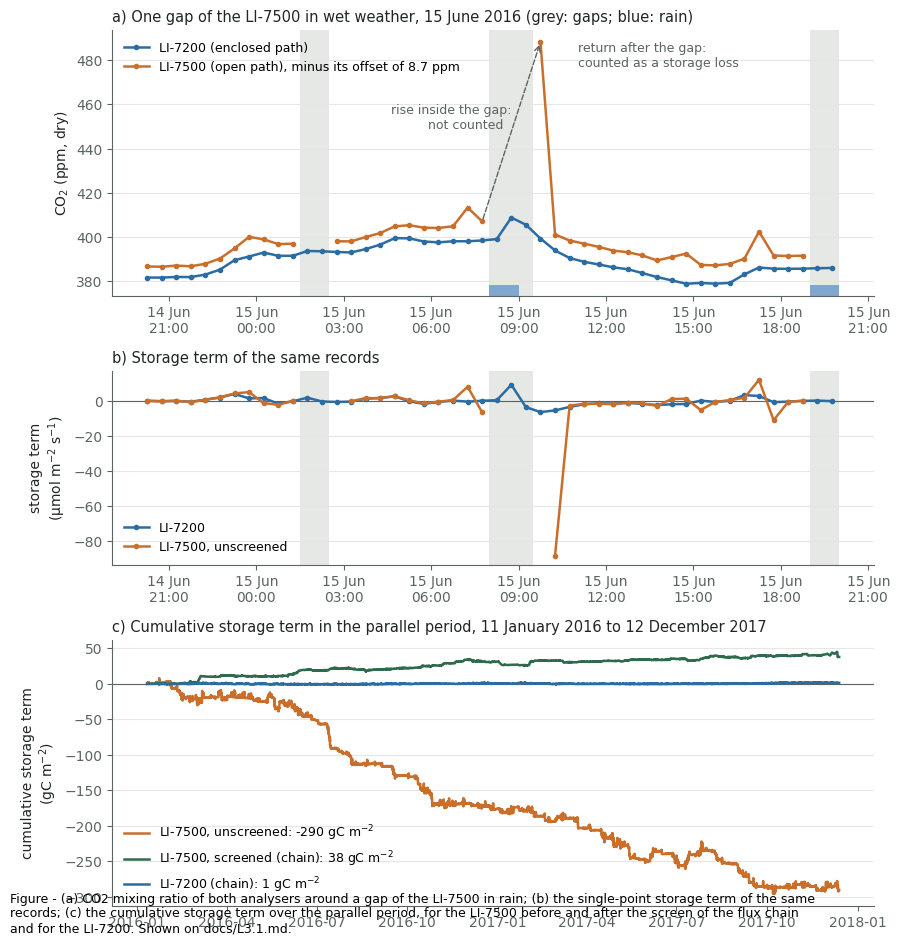

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(9, 9.5), gridspec_kw=dict(height_ratios=[1.1, 0.8, 1.1]))
w = slice(*EXAMPLE)
c75, c72 = raw75.loc[w, CO2] - OFFSET75, raw72.loc[w, CO2]
half = pd.Timedelta('15min')

# Gaps of the LI-7500 concentration and rain, in the two example panels
for g in GAPS:
    for a in ax[:2]:
        a.axvspan(g[0] - half, g[-1] + half, color=GAP, lw=0)
_rain = prec.loc[w]
for t in _rain[_rain > 0].index:
    ax[0].axvspan(t - half, t + half, ymin=0, ymax=0.04, color=RAIN, lw=0)

ax[0].plot(c72.index, c72, color=C72, lw=1.8, marker='o', ms=3, label='LI-7200 (enclosed path)')
ax[0].plot(c75.index, c75, color=C75, lw=1.8, marker='o', ms=3,
           label=f'LI-7500 (open path), minus its offset of {OFFSET75} ppm')
ax[0].annotate('', xy=(c75.index[I1], c75.iloc[I1]), xytext=(c75.index[I0], c75.iloc[I0]),
               arrowprops=dict(arrowstyle='->', color=MUTED, ls='--'))
ax[0].text(GAP_MAIN[len(GAP_MAIN) // 2], (c75.iloc[I0] + c75.iloc[I1]) / 2, 'rise inside the gap:\nnot counted  ',
           ha='right', va='bottom', fontsize=9, color=MUTED)
ax[0].text(c75.index[I1 + 2], c75.iloc[I1], '  return after the gap:\n  counted as a storage loss',
           ha='left', va='top', fontsize=9, color=MUTED)
ax[0].set_ylabel('CO$_2$ (ppm, dry)')
ax[0].legend(loc='upper left', frameon=False, fontsize=9)
ax[0].set_title('a) One gap of the LI-7500 in wet weather, 15 June 2016 (grey: gaps; blue: rain)',
                loc='left', fontsize=10.5, color=INK)

ax[1].axhline(0, color=MUTED, lw=0.8)
ax[1].plot(raw72.loc[w, SC].index, raw72.loc[w, SC], color=C72, lw=1.8, marker='o', ms=3, label='LI-7200')
ax[1].plot(raw75.loc[w, SC].index, raw75.loc[w, SC], color=C75, lw=1.8, marker='o', ms=3,
           label='LI-7500, unscreened')
ax[1].set_ylabel('storage term\n(µmol m$^{-2}$ s$^{-1}$)')
ax[1].legend(loc='lower left', frameon=False, fontsize=9)
ax[1].set_title('b) Storage term of the same records', loc='left', fontsize=10.5, color=INK)
for a in ax[:2]:
    a.xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))

p = slice(*PARALLEL)
cum = {'LI-7500, unscreened': (raw75.loc[p, SC], C75),
       'LI-7500, screened (chain)': (sc75.loc[p], C75_SCREENED),
       'LI-7200 (chain)': (sc72.loc[p], C72)}
CUM_END = {}
ax[2].axhline(0, color=MUTED, lw=0.8)
for label, (s, color) in cum.items():
    c = s.fillna(0).cumsum() * UMOL_TO_GC
    CUM_END[label] = c.iloc[-1]
    ax[2].plot(c.index, c, color=color, lw=1.8, label=f'{label}: {c.iloc[-1]:.0f} gC m$^{{-2}}$')
ax[2].set_ylabel('cumulative storage term\n(gC m$^{-2}$)')
ax[2].legend(loc='lower left', frameon=False, fontsize=9)
ax[2].set_title('c) Cumulative storage term in the parallel period, 11 January 2016 to 12 December 2017',
                loc='left', fontsize=10.5, color=INK)
for a in ax:
    a.grid(axis='y', color=GRID, lw=0.8)

fig.tight_layout()
save_for_docs(fig, 'STORAGE_IRGA75_drift.png')
figcap(fig, "(a) CO2 mixing ratio of both analysers around a gap of the LI-7500 in rain; (b) the single-point "
            "storage term of the same records; (c) the cumulative storage term over the parallel period, for "
            "the LI-7500 before and after the screen of the flux chain and for the LI-7200. "
            "Shown on docs/L3.1.md.")
plt.show()

### 📋 Table: cumulative storage term at the end of the parallel period

In [6]:
display(pd.Series(CUM_END, name='gC m-2').round(0).to_frame()
        .style.set_caption("Table - cumulative storage term from 11 January 2016 to 12 December 2017, "
                           "the end points of panel (c)"))

,gC m-2
"LI-7500, unscreened",-290.000000
"LI-7500, screened (chain)",38.000000
LI-7200 (chain),1.000000


## ⏱️ Runtime

In [7]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}, "
      f"runtime {datetime.now() - NOTEBOOK_START}")

Finished: 2026-11-06 16:03:56, runtime 0:00:01.445118
